In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.multioutput import MultiOutputClassifier
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score


In [32]:
order = pd.read_csv("olist_orders_dataset.csv")
reviews = pd.read_csv("olist_order_reviews_dataset.csv")
items = pd.read_csv("olist_order_items_dataset.csv")
payment = pd.read_csv("olist_order_payments_dataset.csv")
product = pd.read_csv("olist_products_dataset.csv")

df = (order
      .merge(reviews, on="order_id", how="left")
      .merge(items, on="order_id", how="left")
      .merge(payment, on="order_id", how="left")
      .merge(product, on="product_id", how="left")
      )

In [33]:
df = df.head(15000)

In [34]:
df1 = df

In [35]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 32 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   order_id                       15000 non-null  object 
 1   customer_id                    15000 non-null  object 
 2   order_status                   15000 non-null  object 
 3   order_purchase_timestamp       15000 non-null  object 
 4   order_approved_at              14976 non-null  object 
 5   order_delivered_carrier_date   14761 non-null  object 
 6   order_delivered_customer_date  14605 non-null  object 
 7   order_estimated_delivery_date  15000 non-null  object 
 8   review_id                      14914 non-null  object 
 9   review_score                   14914 non-null  float64
 10  review_comment_title           1745 non-null   object 
 11  review_comment_message         6229 non-null   object 
 12  review_creation_date           14914 non-null 

In [36]:
df1.nunique().sort_values()

review_score                         5
payment_type                         5
order_status                         7
order_item_id                       12
product_photos_qty                  15
payment_installments                19
payment_sequential                  22
product_name_lenght                 57
product_category_name               71
product_width_cm                    78
product_height_cm                   89
product_length_cm                   93
order_estimated_delivery_date      426
review_creation_date               566
review_comment_title               822
product_weight_g                  1151
seller_id                         1786
product_description_lenght        2020
price                             2205
freight_value                     3155
review_comment_message            4832
product_id                        8052
payment_value                     8549
order_delivered_carrier_date     11921
order_delivered_customer_date    12225
order_approved_at        

In [37]:
df1 = df1.drop(columns=[
    'order_id', 'customer_id', 'review_id', 'product_id', 'seller_id', 'order_item_id',
    'product_photos_qty', 'shipping_limit_date', 'review_comment_title',
    'review_comment_message', 'review_answer_timestamp'
])
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 21 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   order_status                   15000 non-null  object 
 1   order_purchase_timestamp       15000 non-null  object 
 2   order_approved_at              14976 non-null  object 
 3   order_delivered_carrier_date   14761 non-null  object 
 4   order_delivered_customer_date  14605 non-null  object 
 5   order_estimated_delivery_date  15000 non-null  object 
 6   review_score                   14914 non-null  float64
 7   review_creation_date           14914 non-null  object 
 8   price                          14898 non-null  float64
 9   freight_value                  14898 non-null  float64
 10  payment_sequential             15000 non-null  float64
 11  payment_type                   15000 non-null  object 
 12  payment_installments           15000 non-null 

In [38]:
df1 = df1.dropna()

In [39]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 14321 entries, 0 to 14999
Data columns (total 21 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   order_status                   14321 non-null  object 
 1   order_purchase_timestamp       14321 non-null  object 
 2   order_approved_at              14321 non-null  object 
 3   order_delivered_carrier_date   14321 non-null  object 
 4   order_delivered_customer_date  14321 non-null  object 
 5   order_estimated_delivery_date  14321 non-null  object 
 6   review_score                   14321 non-null  float64
 7   review_creation_date           14321 non-null  object 
 8   price                          14321 non-null  float64
 9   freight_value                  14321 non-null  float64
 10  payment_sequential             14321 non-null  float64
 11  payment_type                   14321 non-null  object 
 12  payment_installments           14321 non-null  floa

In [40]:
data_cols = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date',
    'review_creation_date'
]

for col in data_cols:
    df1[col] = pd.to_datetime(df1[col], errors='coerce')
    
df1.info()   

<class 'pandas.core.frame.DataFrame'>
Index: 14321 entries, 0 to 14999
Data columns (total 21 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_status                   14321 non-null  object        
 1   order_purchase_timestamp       14321 non-null  datetime64[ns]
 2   order_approved_at              14321 non-null  datetime64[ns]
 3   order_delivered_carrier_date   14321 non-null  datetime64[ns]
 4   order_delivered_customer_date  14321 non-null  datetime64[ns]
 5   order_estimated_delivery_date  14321 non-null  datetime64[ns]
 6   review_score                   14321 non-null  float64       
 7   review_creation_date           14321 non-null  datetime64[ns]
 8   price                          14321 non-null  float64       
 9   freight_value                  14321 non-null  float64       
 10  payment_sequential             14321 non-null  float64       
 11  payment_type        

In [41]:
cat_cols = ['product_category_name', 'payment_type', 'order_status']

from sklearn.preprocessing import LabelEncoder

for col in cat_cols:
    le = LabelEncoder()
    df1[col] = le.fit_transform(df1[col].astype(str))
    
print(df1[cat_cols].head())

   product_category_name  payment_type  order_status
0                     69             1             1
1                     69             3             1
2                     69             3             1
3                     60             0             1
4                      7             1             1


In [42]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 14321 entries, 0 to 14999
Data columns (total 21 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_status                   14321 non-null  int64         
 1   order_purchase_timestamp       14321 non-null  datetime64[ns]
 2   order_approved_at              14321 non-null  datetime64[ns]
 3   order_delivered_carrier_date   14321 non-null  datetime64[ns]
 4   order_delivered_customer_date  14321 non-null  datetime64[ns]
 5   order_estimated_delivery_date  14321 non-null  datetime64[ns]
 6   review_score                   14321 non-null  float64       
 7   review_creation_date           14321 non-null  datetime64[ns]
 8   price                          14321 non-null  float64       
 9   freight_value                  14321 non-null  float64       
 10  payment_sequential             14321 non-null  float64       
 11  payment_type        

In [43]:
df1['is_late'] = (df1['order_delivered_customer_date'] > df1['order_estimated_delivery_date']).astype(int)
df1['bad_review'] = (df1['review_score'] <= 3).astype(int)

print(df1[['is_late', 'bad_review']].value_counts(normalize=True))

is_late  bad_review
0        0             0.747364
         1             0.174359
1        1             0.052790
         0             0.025487
Name: proportion, dtype: float64


In [44]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 14321 entries, 0 to 14999
Data columns (total 23 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_status                   14321 non-null  int64         
 1   order_purchase_timestamp       14321 non-null  datetime64[ns]
 2   order_approved_at              14321 non-null  datetime64[ns]
 3   order_delivered_carrier_date   14321 non-null  datetime64[ns]
 4   order_delivered_customer_date  14321 non-null  datetime64[ns]
 5   order_estimated_delivery_date  14321 non-null  datetime64[ns]
 6   review_score                   14321 non-null  float64       
 7   review_creation_date           14321 non-null  datetime64[ns]
 8   price                          14321 non-null  float64       
 9   freight_value                  14321 non-null  float64       
 10  payment_sequential             14321 non-null  float64       
 11  payment_type        

In [45]:
dt_col = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date',
            'order_estimated_delivery_date', 'review_creation_date']

for col in dt_col:
    df1[col + '_year'] = df1[col].dt.year
    df1[col + '_month'] = df1[col].dt.month
    df1[col + '_day'] = df1[col].dt.day
    df1[col + '_dow'] = df1[col].dt.dayofweek
    df1[col + '_hour'] = df1[col].dt.hour
    
    
df1 = df1.drop(columns=dt_col)
df1.info()


<class 'pandas.core.frame.DataFrame'>
Index: 14321 entries, 0 to 14999
Data columns (total 47 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   order_status                         14321 non-null  int64  
 1   review_score                         14321 non-null  float64
 2   price                                14321 non-null  float64
 3   freight_value                        14321 non-null  float64
 4   payment_sequential                   14321 non-null  float64
 5   payment_type                         14321 non-null  int64  
 6   payment_installments                 14321 non-null  float64
 7   payment_value                        14321 non-null  float64
 8   product_category_name                14321 non-null  int64  
 9   product_name_lenght                  14321 non-null  float64
 10  product_description_lenght           14321 non-null  float64
 11  product_weight_g                 

In [46]:
df1[['is_late', 'bad_review']].value_counts()

is_late  bad_review
0        0             10703
         1              2497
1        1               756
         0               365
Name: count, dtype: int64

In [47]:
X = df1.drop(columns=['is_late', 'bad_review'])
y = df1[['is_late', 'bad_review']]

stratify = y['is_late'].astype(str)+'_'+y['bad_review'].astype(str)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.20, random_state=42, stratify=stratify)



In [48]:
dt = DecisionTreeClassifier(max_depth=8,class_weight='balanced' ,random_state=42)
multi_tree = MultiOutputClassifier(dt)
multi_tree.fit(X_train, y_train)

,estimator,DecisionTreeC...ndom_state=42)
,n_jobs,None
,criterion,'gini'
,splitter,'best'
,max_depth,8
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None


In [49]:
y_pred = multi_tree.predict(X_test)


print('Classification Report for is_late:', classification_report(y_test['is_late'], y_pred[:, 0]))
print("Classification Report for bad_reveiw:", classification_report(y_test['bad_review'], y_pred[:, 0]))

Classification Report for is_late:               precision    recall  f1-score   support

           0       0.97      0.87      0.92      2641
           1       0.31      0.69      0.42       224

    accuracy                           0.85      2865
   macro avg       0.64      0.78      0.67      2865
weighted avg       0.92      0.85      0.88      2865

Classification Report for bad_reveiw:               precision    recall  f1-score   support

           0       0.88      0.94      0.91      2214
           1       0.73      0.56      0.63       651

    accuracy                           0.85      2865
   macro avg       0.80      0.75      0.77      2865
weighted avg       0.84      0.85      0.85      2865



In [50]:
dt_gini = DecisionTreeClassifier(criterion='gini',max_depth=8,class_weight='balanced' ,random_state=42)
multi_gini = MultiOutputClassifier(dt_gini)
multi_gini.fit(X_train, y_train)

dt_entropy = DecisionTreeClassifier(criterion='entropy',max_depth=8,class_weight='balanced' ,random_state=42)
multi_entropy = MultiOutputClassifier(dt_entropy)
multi_entropy.fit(X_train, y_train)


y_gini_pred = multi_gini.predict(X_test)
y_entropy_pred = multi_entropy.predict(X_test)

print('Classification Report Gini is_late:', classification_report(y_test['is_late'], y_gini_pred[:, 0]))
print('Classification Report Entropy is_late:', classification_report(y_test['is_late'], y_entropy_pred[:, 0]))

print("Classification Report Gini bad_reveiw:", classification_report(y_test['bad_review'], y_gini_pred[:, 0]))
print("Classification Report Entropy bad_reveiw:", classification_report(y_test['bad_review'], y_entropy_pred[:, 0]))


Classification Report Gini is_late:               precision    recall  f1-score   support

           0       0.97      0.87      0.92      2641
           1       0.31      0.69      0.42       224

    accuracy                           0.85      2865
   macro avg       0.64      0.78      0.67      2865
weighted avg       0.92      0.85      0.88      2865

Classification Report Entropy is_late:               precision    recall  f1-score   support

           0       0.97      0.88      0.92      2641
           1       0.32      0.67      0.43       224

    accuracy                           0.86      2865
   macro avg       0.64      0.77      0.67      2865
weighted avg       0.92      0.86      0.88      2865

Classification Report Gini bad_reveiw:               precision    recall  f1-score   support

           0       0.88      0.94      0.91      2214
           1       0.73      0.56      0.63       651

    accuracy                           0.85      2865
   macro avg  

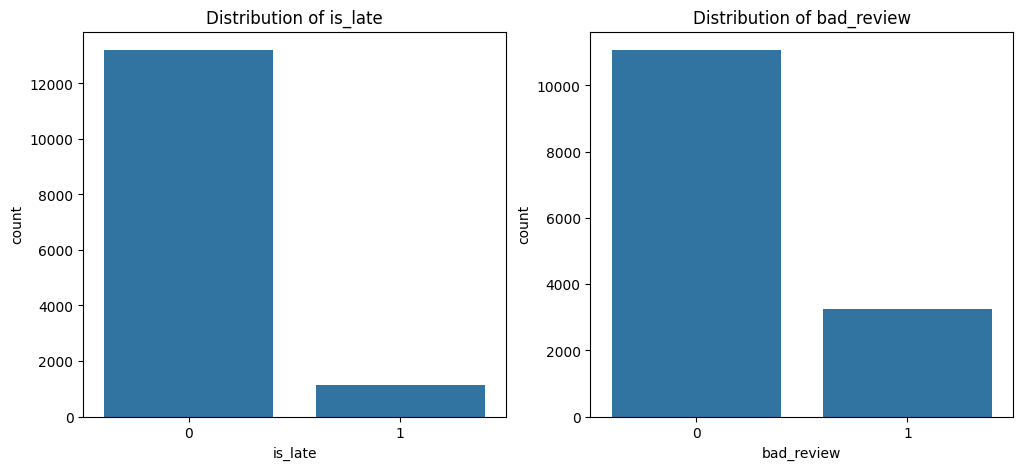

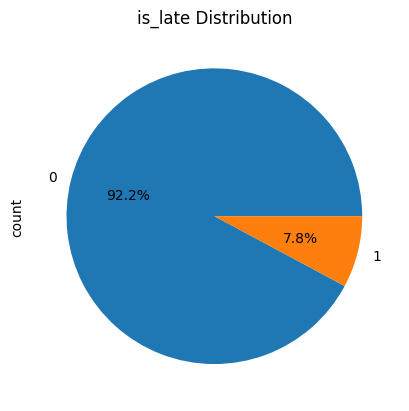

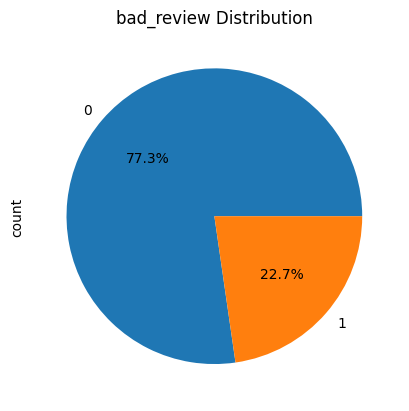

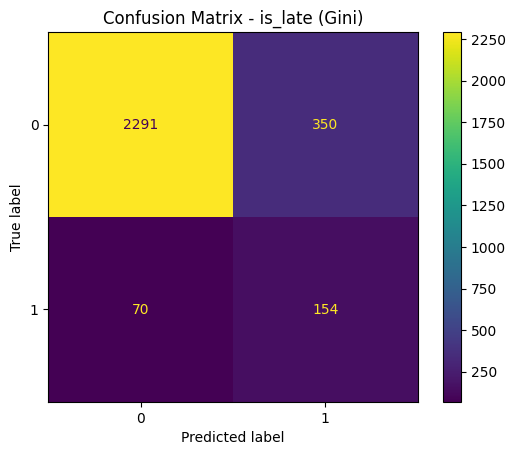

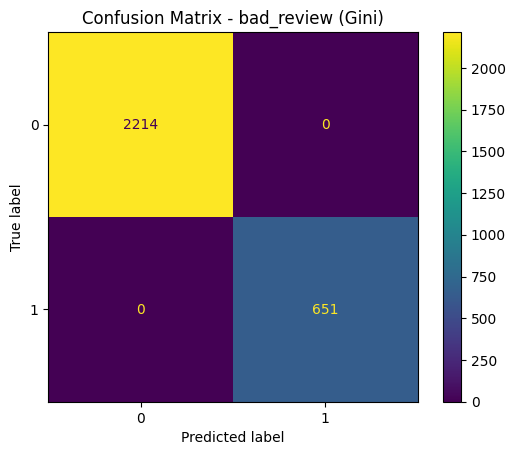

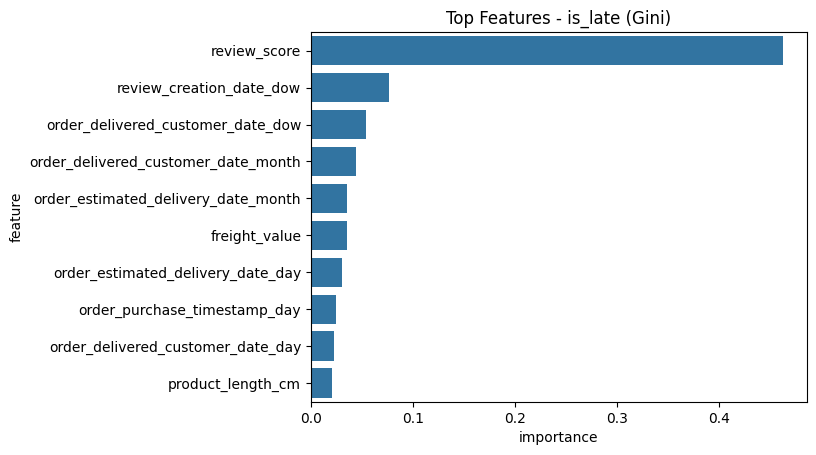

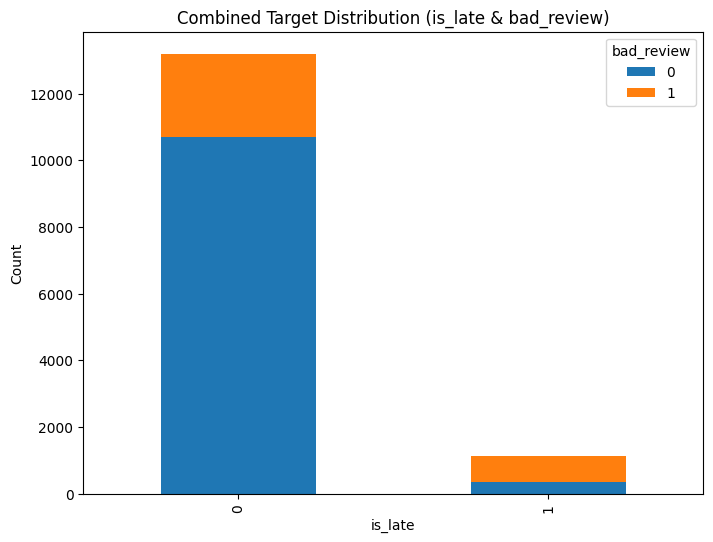

|--- review_score <= 3.50
|   |--- review_creation_date_dow <= 1.50
|   |   |--- order_purchase_timestamp_day <= 22.50
|   |   |   |--- price <= 277.44
|   |   |   |   |--- product_length_cm <= 58.50
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- product_length_cm >  58.50
|   |   |   |   |   |--- product_weight_g <= 1425.00
|   |   |   |   |   |   |--- order_approved_at_day <= 14.00
|   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |--- order_approved_at_day >  14.00
|   |   |   |   |   |   |   |--- order_purchase_timestamp_year <= 2017.50
|   |   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |   |--- order_purchase_timestamp_year >  2017.50
|   |   |   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |--- product_weight_g >  1425.00
|   |   |   |   |   |   |--- class: 0
|   |   |   |--- price >  277.44
|   |   |   |   |--- order_delivered_customer_date_hour <= 12.50
|   |   |   |   |   |--- product_length_cm <= 27.00
|   |   |   |   |   | 

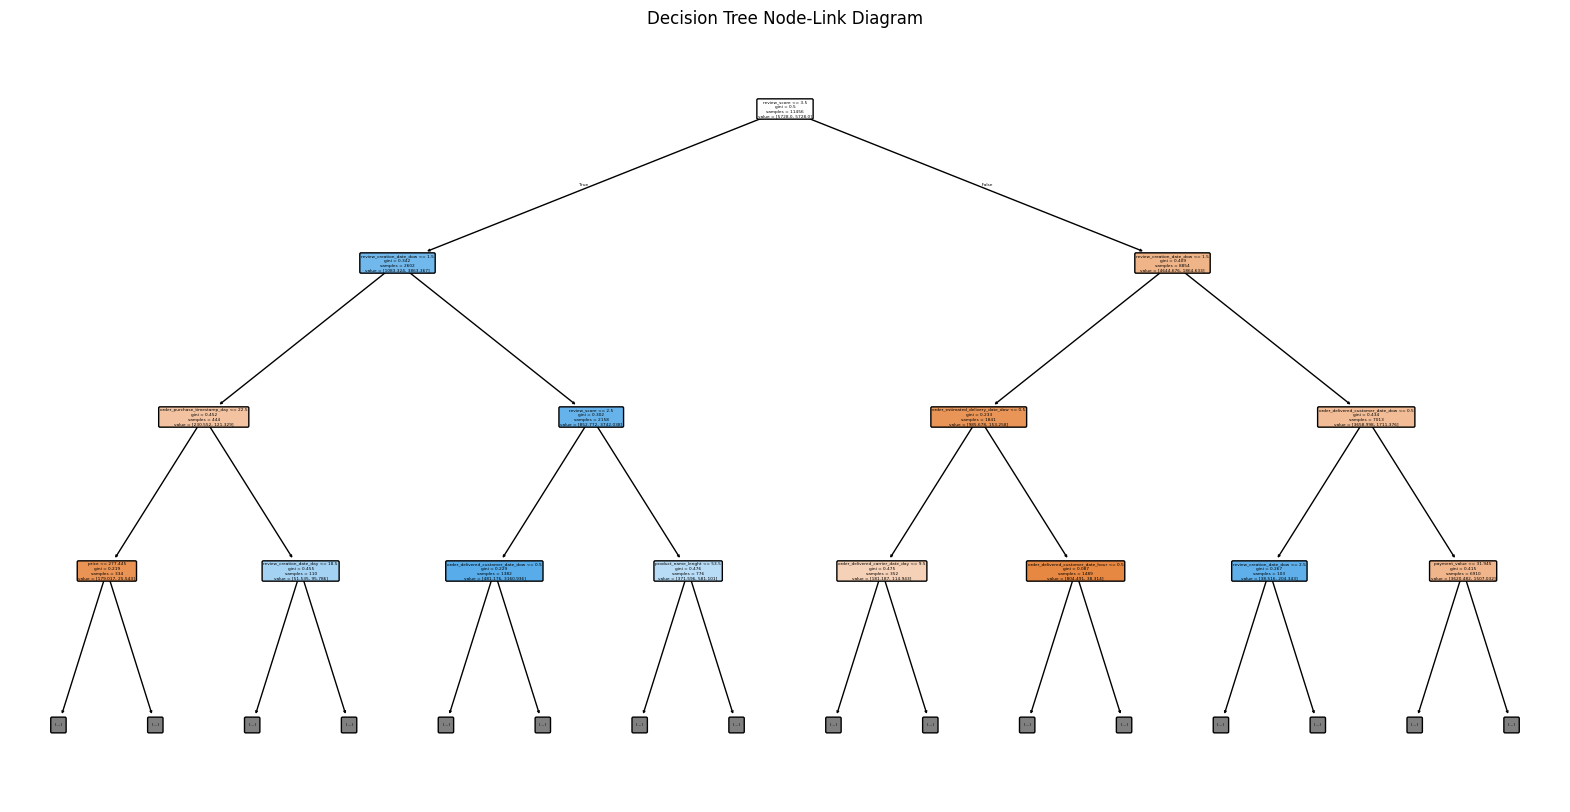

Number of internal nodes: 117
Number of leaf nodes: 118
Feature, Threshold, Samples at each node:
Node 0: feature=1, threshold=3.50, samples=11456
Node 1: feature=43, threshold=1.50, samples=2602
Node 2: feature=17, threshold=22.50, samples=444
Node 3: feature=2, threshold=277.44, samples=334
Node 4: feature=12, threshold=58.50, samples=312
Node 5: feature=-2, threshold=-2.00, samples=285
Node 6: feature=11, threshold=1425.00, samples=27
Node 7: feature=22, threshold=14.00, samples=9
Node 8: feature=-2, threshold=-2.00, samples=6
Node 9: feature=15, threshold=2017.50, samples=3
Node 10: feature=-2, threshold=-2.00, samples=1
Node 11: feature=-2, threshold=-2.00, samples=2
Node 12: feature=-2, threshold=-2.00, samples=18
Node 13: feature=34, threshold=12.50, samples=22
Node 14: feature=12, threshold=27.00, samples=6
Node 15: feature=-2, threshold=-2.00, samples=4
Node 16: feature=35, threshold=2017.50, samples=2
Node 17: feature=-2, threshold=-2.00, samples=1
Node 18: feature=-2, thresh

In [51]:
# -----------------------------
# Required Libraries
# -----------------------------
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

from sklearn.tree import plot_tree, export_text
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.preprocessing import label_binarize

# For icicle plots
!pip install plotly
import plotly.express as px

# -----------------------------
# 1️⃣ Target Distribution Plots
# -----------------------------
def plot_target_distribution(df, targets=['is_late','bad_review']):
    plt.figure(figsize=(12,5))
    for i, target in enumerate(targets):
        plt.subplot(1,len(targets),i+1)
        sns.countplot(x=target, data=df)
        plt.title(f"Distribution of {target}")
    plt.show()
    
    for target in targets:
        df[target].value_counts().plot.pie(autopct='%1.1f%%', title=f"{target} Distribution")
        plt.show()

# -----------------------------
# 2️⃣ Confusion Matrices
# -----------------------------
def plot_confusion(y_true, y_pred, title):
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred)
    plt.title(title)
    plt.show()

# -----------------------------
# 3️⃣ Feature Importance Bar Plot
# -----------------------------
def plot_feature_importance(model, X_train, top_n=10, title="Feature Importance"):
    importances = model.feature_importances_
    feat_imp = pd.DataFrame({'feature': X_train.columns, 'importance': importances})
    feat_imp = feat_imp.sort_values('importance', ascending=False).head(top_n)
    sns.barplot(x='importance', y='feature', data=feat_imp)
    plt.title(title)
    plt.show()

# -----------------------------
# 4️⃣ Multi-target Stacked Bar
# -----------------------------
def plot_stacked_targets(df, target1='is_late', target2='bad_review'):
    df.groupby([target1,target2]).size().unstack().plot(kind='bar', stacked=True, figsize=(8,6))
    plt.title(f"Combined Target Distribution ({target1} & {target2})")
    plt.xlabel(target1)
    plt.ylabel("Count")
    plt.show()

# -----------------------------
# 5️⃣ Textual Representation of Tree
# -----------------------------
def tree_text(model, feature_names):
    tree_rules = export_text(model, feature_names=list(feature_names))
    print(tree_rules)

# -----------------------------
# 6️⃣ Node-Link / Tree Diagram
# -----------------------------
def plot_node_link(model, feature_names, max_depth=3, title="Decision Tree Node-Link Diagram"):
    plt.figure(figsize=(20,10))
    plot_tree(model, feature_names=feature_names, filled=True, rounded=True, max_depth=max_depth)
    plt.title(title)
    plt.show()

# -----------------------------
# 7️⃣ Icicle Plot for Tree
# -----------------------------
def plot_icicle(model, feature_names):
    # Recursive function to get tree structure
    def recurse(node_id, parent_name, tree_, feature_names_, labels):
        if tree_.feature[node_id] != -2:  # not leaf
            feat = feature_names_[tree_.feature[node_id]]
            threshold = tree_.threshold[node_id]
            left = f"{feat} <= {threshold:.2f}"
            right = f"{feat} > {threshold:.2f}"
            labels.append(dict(Parent=parent_name, Child=left))
            labels.append(dict(Parent=parent_name, Child=right))
            recurse(tree_.children_left[node_id], left, tree_, feature_names_, labels)
            recurse(tree_.children_right[node_id], right, tree_, feature_names_, labels)
    labels = []
    recurse(0, "Root", model.tree_, feature_names, labels)
    df_icicle = pd.DataFrame(labels)
    fig = px.icicle(df_icicle, path=['Parent','Child'])
    fig.show()

# -----------------------------
# 8️⃣ Decision Surface Plot (only works for 2 features)
# -----------------------------
from sklearn.inspection import DecisionBoundaryDisplay
def plot_decision_surface(model, X, y, features=[0,1], title="Decision Surface"):
    X_plot = X.iloc[:, features].to_numpy()
    y_plot = y.iloc[:, features[0]].to_numpy()  # For one target, adjust as needed
    disp = DecisionBoundaryDisplay.from_estimator(model, X_plot, response_method="predict", cmap=plt.cm.RdYlBu)
    plt.scatter(X_plot[:,0], X_plot[:,1], c=y_plot, edgecolor='k', cmap=plt.cm.RdYlBu)
    plt.xlabel(X.columns[features[0]])
    plt.ylabel(X.columns[features[1]])
    plt.title(title)
    plt.show()

# -----------------------------
# 9️⃣ Internal Nodes & Leaf Nodes Info
# -----------------------------
def print_tree_nodes(model):
    tree_ = model.tree_
    print(f"Number of internal nodes: {tree_.node_count - np.count_nonzero(tree_.children_left == -1)}")
    print(f"Number of leaf nodes: {np.count_nonzero(tree_.children_left == -1)}")
    print("Feature, Threshold, Samples at each node:")
    for i in range(tree_.node_count):
        print(f"Node {i}: feature={tree_.feature[i]}, threshold={tree_.threshold[i]:.2f}, samples={tree_.n_node_samples[i]}")

# -----------------------------
# 🚀 Pipeline Execution
# -----------------------------
# Example: Run all for multi_gini first output (is_late)
plot_target_distribution(df1)
plot_confusion(y_test['is_late'], y_gini_pred[:,0], "Confusion Matrix - is_late (Gini)")
plot_confusion(y_test['bad_review'], y_gini_pred[:,1], "Confusion Matrix - bad_review (Gini)")
plot_feature_importance(multi_gini.estimators_[0], X_train, title="Top Features - is_late (Gini)")
plot_stacked_targets(df1)
tree_text(multi_gini.estimators_[0], X_train.columns)
plot_node_link(multi_gini.estimators_[0], X_train.columns)
plot_icicle(multi_gini.estimators_[0], X_train.columns)
# For decision surface, pick any 2 features index, e.g., [0,1]
# plot_decision_surface(multi_gini.estimators_[0], X_test, y_test['is_late'], features=[0,1])
print_tree_nodes(multi_gini.estimators_[0])



================ Gini Model ================


---- Target: is_late ----

Textual Tree - is_late (Gini):
|--- review_score <= 3.50
|   |--- review_creation_date_dow <= 1.50
|   |   |--- order_purchase_timestamp_day <= 22.50
|   |   |   |--- price <= 277.44
|   |   |   |   |--- product_length_cm <= 58.50
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- product_length_cm >  58.50
|   |   |   |   |   |--- product_weight_g <= 1425.00
|   |   |   |   |   |   |--- order_approved_at_day <= 14.00
|   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |--- order_approved_at_day >  14.00
|   |   |   |   |   |   |   |--- order_purchase_timestamp_year <= 2017.50
|   |   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |   |--- order_purchase_timestamp_year >  2017.50
|   |   |   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |--- product_weight_g >  1425.00
|   |   |   |   |   |   |--- class: 0
|   |   |   |--- price >  277.44
|   |   |   |   |--- order_delive

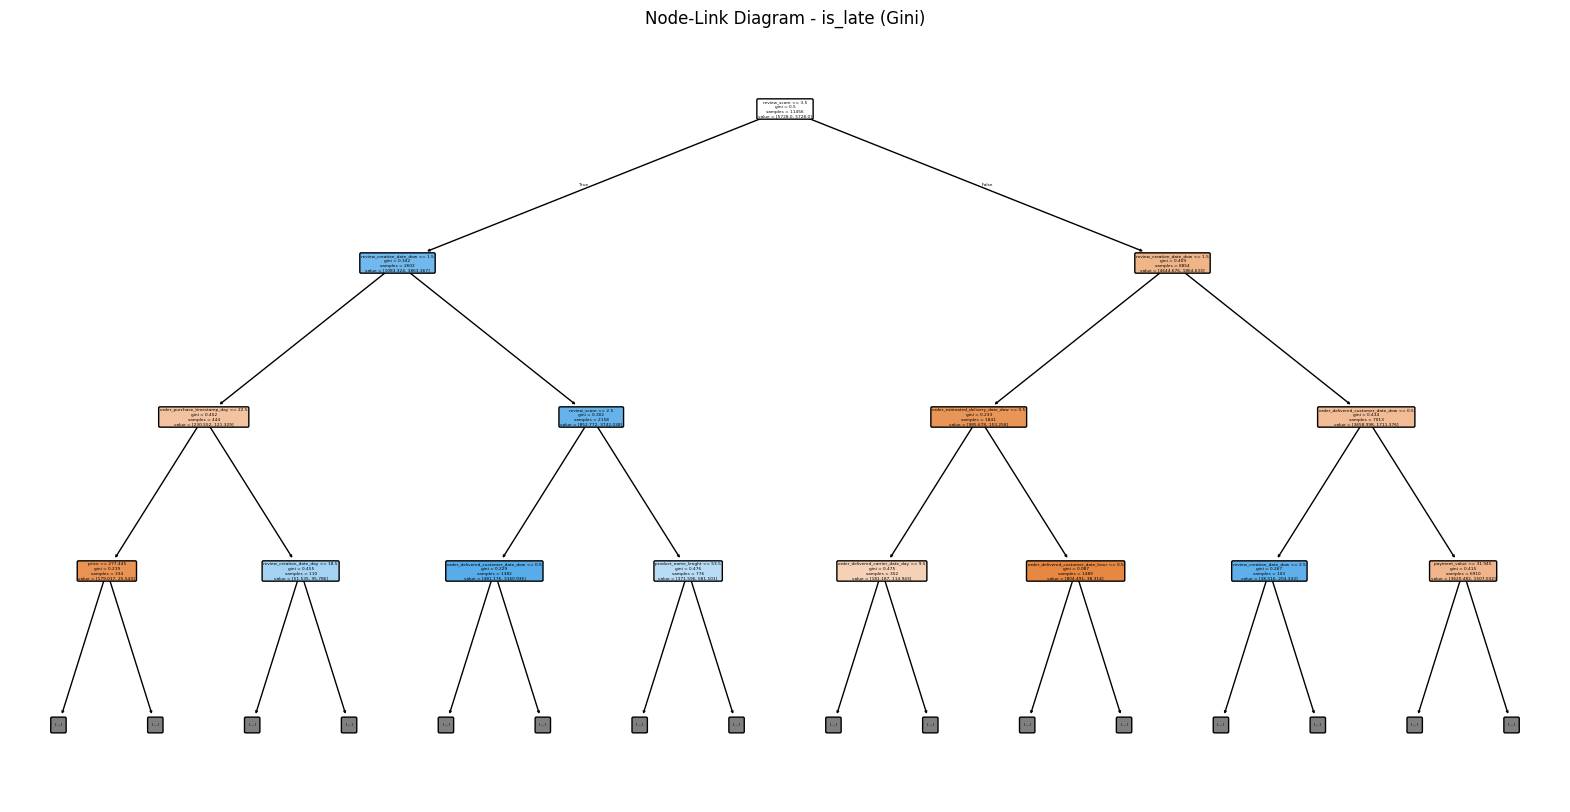


---- Target: bad_review ----

Textual Tree - bad_review (Gini):
|--- review_score <= 3.50
|   |--- class: 1
|--- review_score >  3.50
|   |--- product_weight_g <= 26.00
|   |   |--- class: 0
|   |--- product_weight_g >  26.00
|   |   |--- class: 0



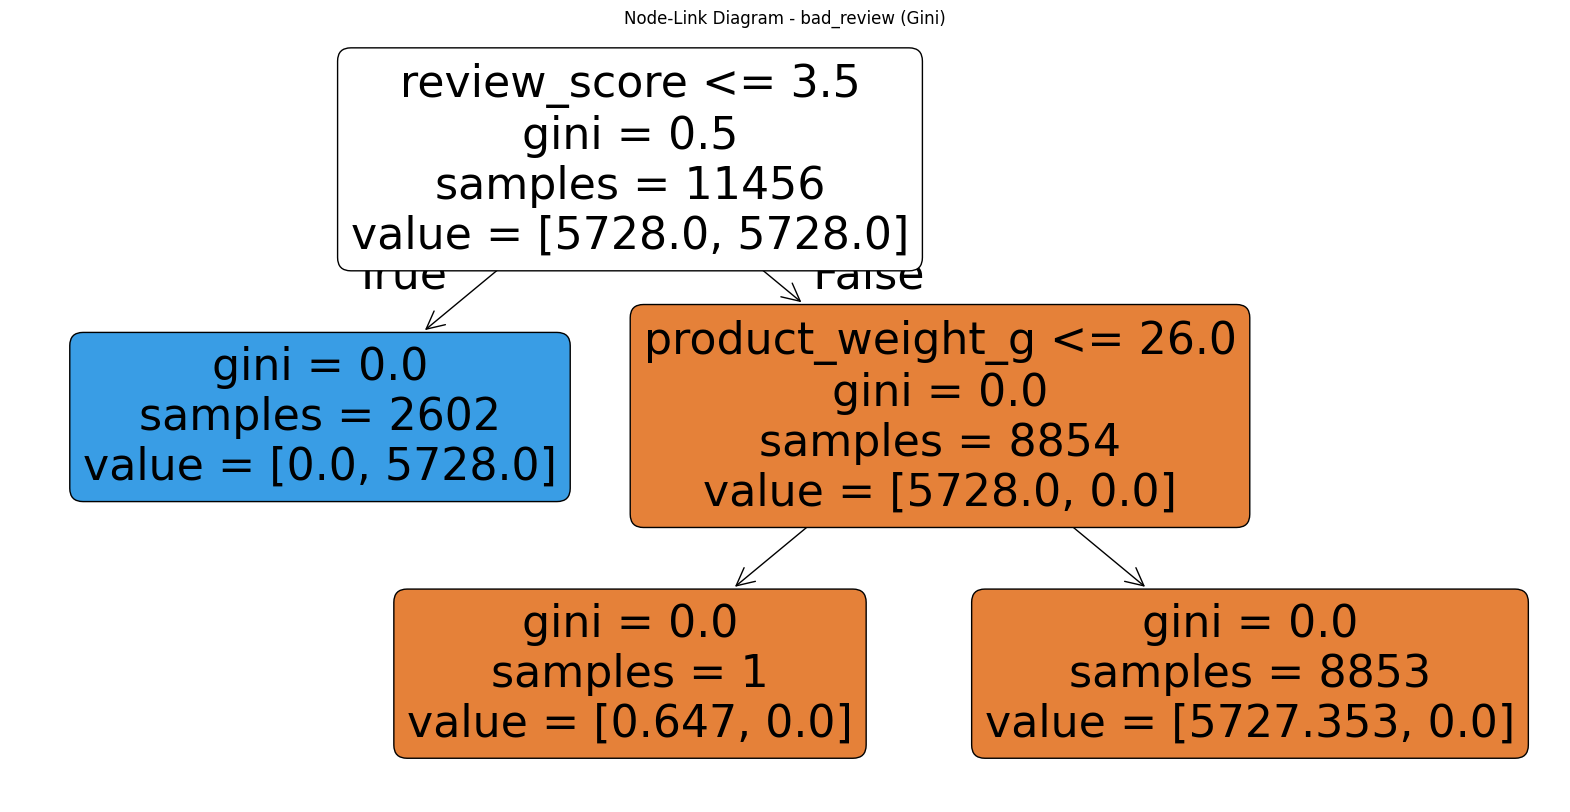


================ Entropy Model ================


---- Target: is_late ----

Textual Tree - is_late (Entropy):
|--- review_score <= 3.50
|   |--- review_creation_date_dow <= 1.50
|   |   |--- order_purchase_timestamp_day <= 22.50
|   |   |   |--- order_estimated_delivery_date_month <= 4.50
|   |   |   |   |--- product_length_cm <= 27.50
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- product_length_cm >  27.50
|   |   |   |   |   |--- order_estimated_delivery_date_day <= 12.00
|   |   |   |   |   |   |--- order_delivered_customer_date_year <= 2017.50
|   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |--- order_delivered_customer_date_year >  2017.50
|   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |--- order_estimated_delivery_date_day >  12.00
|   |   |   |   |   |   |--- product_width_cm <= 25.50
|   |   |   |   |   |   |   |--- order_purchase_timestamp_hour <= 18.50
|   |   |   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |   |   |--- or

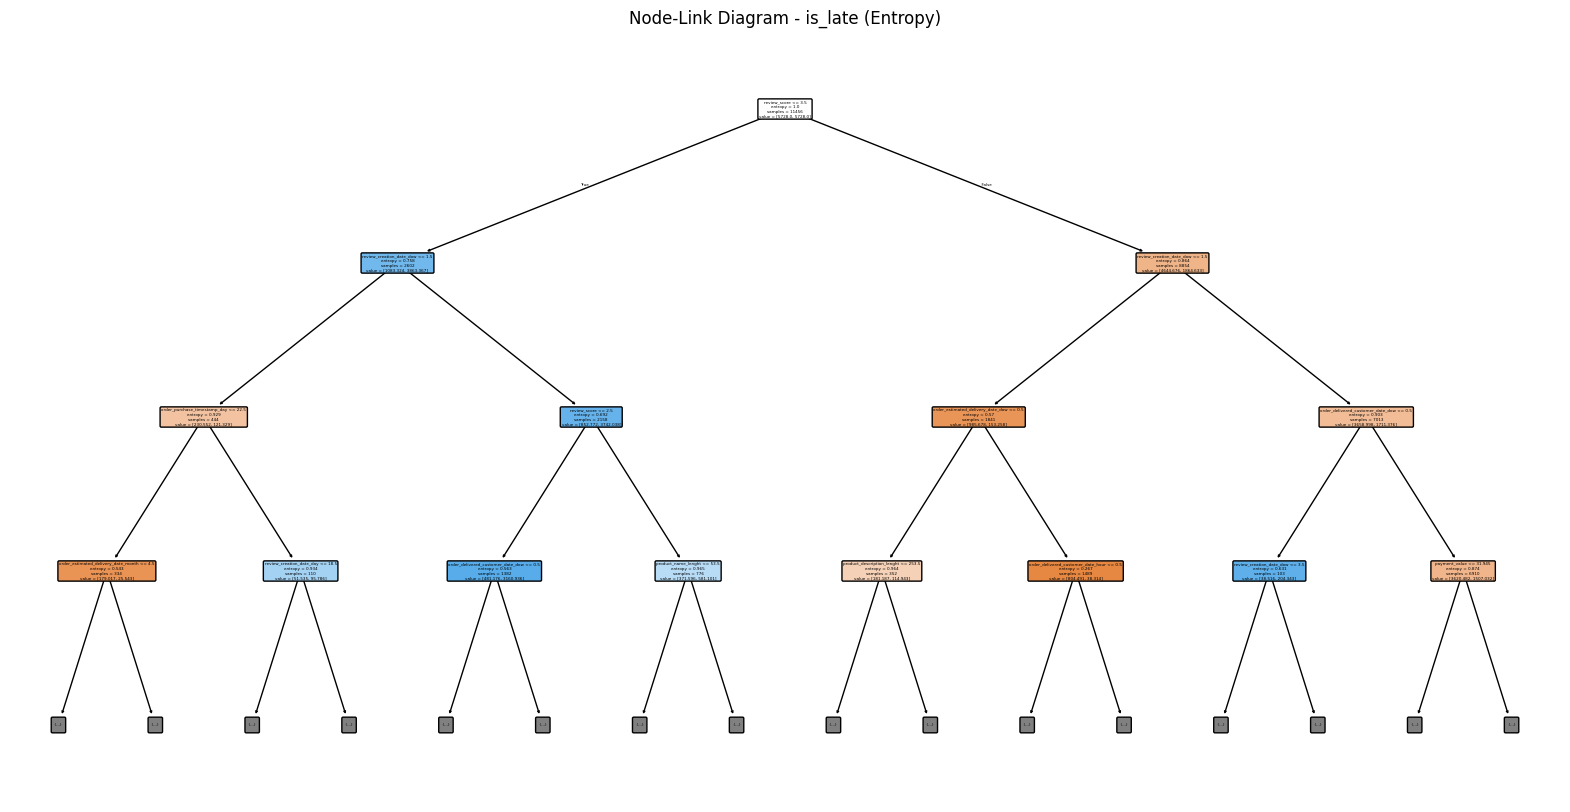


---- Target: bad_review ----

Textual Tree - bad_review (Entropy):
|--- review_score <= 3.50
|   |--- class: 1
|--- review_score >  3.50
|   |--- product_weight_g <= 26.00
|   |   |--- class: 0
|   |--- product_weight_g >  26.00
|   |   |--- class: 0



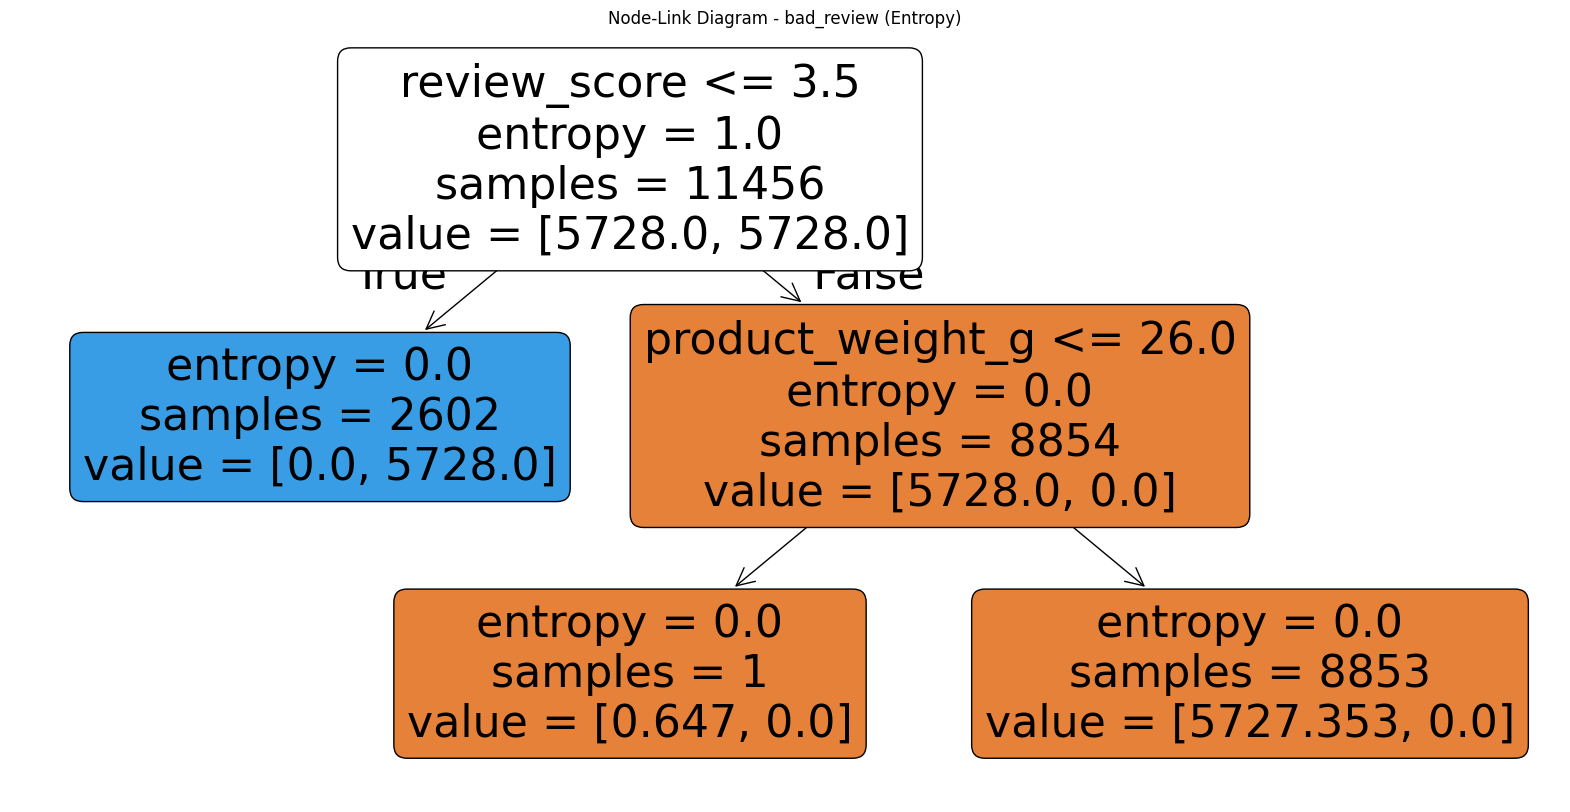

In [52]:
# -----------------------------
# Pipeline: Textual Tree, Node-Link, Icicle
# -----------------------------
models = {
    'Gini': multi_gini,
    'Entropy': multi_entropy
}

targets = {
    'is_late': 0,
    'bad_review': 1
}

for model_name, model in models.items():
    print(f"\n================ {model_name} Model ================\n")
    
    for target_name, idx in targets.items():
        print(f"\n---- Target: {target_name} ----\n")
        
        # 1️⃣ Textual Tree
        print(f"Textual Tree - {target_name} ({model_name}):")
        tree_text(model.estimators_[idx], X_train.columns)
        
        # 2️⃣ Node-Link Diagram
        plot_node_link(model.estimators_[idx], X_train.columns,
                       title=f"Node-Link Diagram - {target_name} ({model_name})")
        
        # 3️⃣ Icicle Plot
        plot_icicle(model.estimators_[idx], X_train.columns)


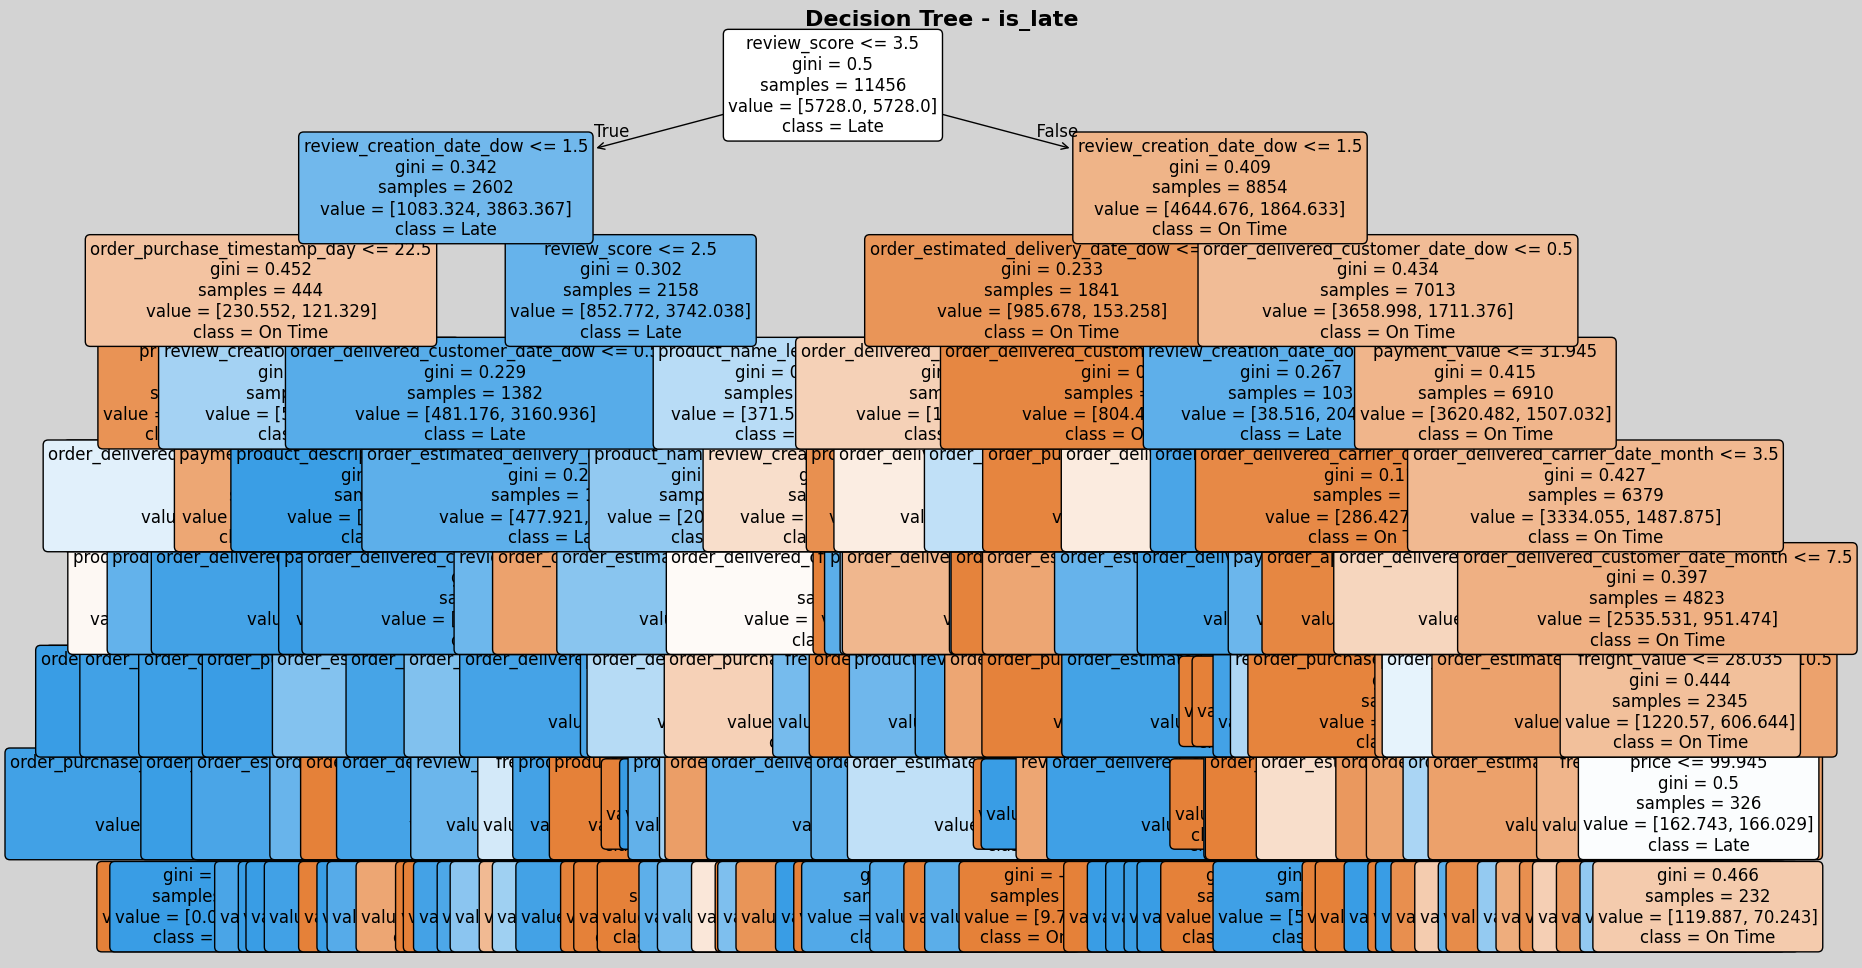


Textual Representation of the Tree for is_late:

|--- review_score <= 3.50
|   |--- review_creation_date_dow <= 1.50
|   |   |--- order_purchase_timestamp_day <= 22.50
|   |   |   |--- price <= 277.44
|   |   |   |   |--- product_length_cm <= 58.50
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- product_length_cm >  58.50
|   |   |   |   |   |--- product_weight_g <= 1425.00
|   |   |   |   |   |   |--- order_approved_at_day <= 14.00
|   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |--- order_approved_at_day >  14.00
|   |   |   |   |   |   |   |--- order_purchase_timestamp_year <= 2017.50
|   |   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |   |--- order_purchase_timestamp_year >  2017.50
|   |   |   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |--- product_weight_g >  1425.00
|   |   |   |   |   |   |--- class: 0
|   |   |   |--- price >  277.44
|   |   |   |   |--- order_delivered_customer_date_hour <= 12.50
|   |   |   |   |   |---

In [53]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree, export_text
import pandas as pd

def plot_decision_tree_pipeline(model, X_train, target_name, class_names=['Class 0','Class 1'],
                                figsize=(20,12), fontsize=12, bg_color='lightgray', max_depth=None):
    """
    Plots a Decision Tree with high resolution, gray background, rounded nodes,
    and shows node split details in a textual form below the plot.
    
    Parameters:
    - model: trained DecisionTreeClassifier
    - X_train: training feature dataframe
    - target_name: string, target column name for title
    - class_names: list of class names for better readability
    - figsize: tuple, figure size
    - fontsize: int, font size for node labels
    - bg_color: string, matplotlib figure background color
    - max_depth: int, maximum depth to show in plot
    """
    
    # 1️⃣ Plot Decision Tree (Node-Link Diagram)
    plt.figure(figsize=figsize, facecolor=bg_color)
    plot_tree(
        model,
        feature_names=X_train.columns,
        class_names=class_names,
        filled=True,
        rounded=True,
        fontsize=fontsize,
        label='all',
        impurity=True,
        max_depth=max_depth
    )
    plt.title(f"Decision Tree - {target_name}", fontsize=16, weight='bold')
    plt.show()
    
    # 2️⃣ Show textual representation with split info
    print(f"\nTextual Representation of the Tree for {target_name}:\n")
    tree_rules = export_text(model, feature_names=list(X_train.columns))
    print(tree_rules)
    
    # 3️⃣ Optional: show internal nodes and leaf node details
    tree_ = model.tree_
    print(f"\nNumber of internal nodes: {tree_.node_count - (tree_.children_left == -1).sum()}")
    print(f"Number of leaf nodes: {(tree_.children_left == -1).sum()}\n")
    
    print("Node Details (Node ID : feature, threshold, samples, gini, predicted class):")
    for i in range(tree_.node_count):
        feature = tree_.feature[i]
        threshold = tree_.threshold[i]
        samples = tree_.n_node_samples[i]
        gini = tree_.impurity[i]
        value = tree_.value[i]
        predicted_class = value.argmax()
        if feature != -2:  # internal node
            feat_name = X_train.columns[feature]
            print(f"Node {i}: {feat_name} <= {threshold:.2f}, samples={samples}, gini={gini:.3f}, predicted={class_names[predicted_class]}")
        else:  # leaf node
            print(f"Leaf Node {i}: samples={samples}, gini={gini:.3f}, predicted={class_names[predicted_class]}")

# -----------------------------
# Example Usage
# -----------------------------
# For multi_gini tree predicting 'is_late'
plot_decision_tree_pipeline(
    model=multi_gini.estimators_[0], 
    X_train=X_train, 
    target_name='is_late', 
    class_names=['On Time','Late'],
    figsize=(20,12),
    fontsize=12,
    bg_color='lightgray',
    max_depth=None  # you can limit depth for clarity
)


## ParaMeter Training

In [57]:
df2 = df1.copy()

In [58]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import StratifiedKFold
X = df2.drop(columns=['is_late', 'bad_review', 'review_score'])
y = df2[['is_late', 'bad_review']]


y_comb = y['is_late'].astype(str) + '_' + y['bad_review'].astype(str)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.20, random_state=42, stratify=y_comb)

y_train_comb = y_train['is_late'].astype(str) + '_' + y_train['bad_review'].astype(str)
sm = SMOTE(random_state=42)
X_train_res, y_train_res_comb = sm.fit_resample(X_train, y_train_comb)

y_train_res = y_train_res_comb.str.split('_', expand=True).astype(int)
y_train_res.columns = ['is_late', 'bad_review']

print("✅ After SMOTE balancing (training data only):")
print(y_train_res.value_counts())



✅ After SMOTE balancing (training data only):
is_late  bad_review
0        0             8562
         1             8562
1        0             8562
         1             8562
Name: count, dtype: int64


In [60]:
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)


param_grid  = {
    'estimator__criterion': ['gini', 'entropy'],
    'estimator__max_depth': [6, 8, 10, None],
    'estimator__min_samples_split': [2, 5, 10, 20],
    'estimator__min_samples_leaf': [1, 2, 4, 6],
    'estimator__class_weight': [None, "balanced"]
}

grid = GridSearchCV(
    MultiOutputClassifier(DecisionTreeClassifier(random_state=42)),
    param_grid,
    scoring='f1_macro',
    cv=skf.split(X_train_res, y_train_res_comb),
    n_jobs=-1,
    verbose=2,
    error_score=0
)


grid.fit(X_train_res, y_train_res)
print("Best Parameters:", grid.best_params_)



Fitting 3 folds for each of 256 candidates, totalling 768 fits
Best Parameters: {'estimator__class_weight': None, 'estimator__criterion': 'entropy', 'estimator__max_depth': None, 'estimator__min_samples_leaf': 1, 'estimator__min_samples_split': 2}


In [ ]:
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

print("\nClassification Report for is_late:")
print(classification_report(y_test['is_late'], y_pred[:, 0]))

print("\nClassification Report for bad_review:")
print(classification_report(y_test['bad_review'], y_pred[:, 1]))